In [2]:

import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

OUTPUT_DIR = Path.cwd()
SAMPLE_RATE = 48000
DURATION = 0.05
FREQUENCY = 1000
NOISE_LEVEL = 0.35
WINDOW_SIZE = 5

print("Acoustic preprocessing notebook initialized.")


Acoustic preprocessing notebook initialized.


In [3]:

time_axis = np.arange(int(SAMPLE_RATE * DURATION)) / SAMPLE_RATE
clean_signal = np.sin(2 * np.pi * FREQUENCY * time_axis)

rng = np.random.default_rng(42)
noise = rng.normal(0, NOISE_LEVEL, len(time_axis))
noisy_signal = clean_signal + noise

print("Total samples:", len(time_axis))
print("Clean and noisy signals generated.")


Total samples: 2400
Clean and noisy signals generated.


In [4]:

kernel = np.ones(WINDOW_SIZE) / WINDOW_SIZE
filtered_signal = np.convolve(noisy_signal, kernel, mode="same")

segment_samples = int(SAMPLE_RATE * 0.01)
segments = [
    filtered_signal[i:i + segment_samples]
    for i in range(0, len(filtered_signal), segment_samples)
]

print("Filter window:", WINDOW_SIZE, "samples")
print("Number of segments:", len(segments))
print("Samples per segment:", segment_samples)


Filter window: 5 samples
Number of segments: 5
Samples per segment: 480


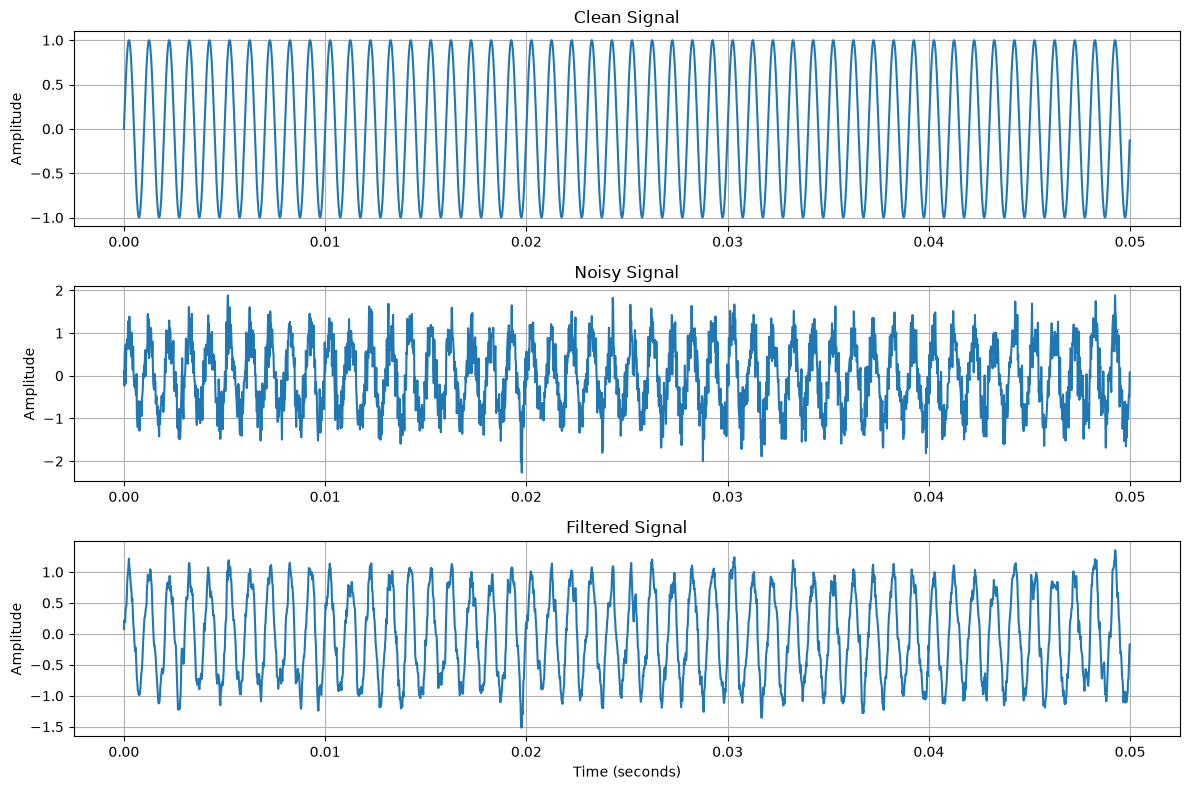

Notebook CSV saved.


In [5]:

fig, axes = plt.subplots(3, 1, figsize=(12, 8))

axes[0].plot(time_axis, clean_signal)
axes[0].set_title("Clean Signal")

axes[1].plot(time_axis, noisy_signal)
axes[1].set_title("Noisy Signal")

axes[2].plot(time_axis, filtered_signal)
axes[2].set_title("Filtered Signal")

for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.grid(True)

axes[2].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

with open(OUTPUT_DIR / "notebook_results.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["time_seconds", "clean", "noisy", "filtered"])
    writer.writerows(zip(time_axis, clean_signal, noisy_signal, filtered_signal))

print("Notebook CSV saved.")


In [6]:
import sys
print("Python:", sys.executable)

import numpy as np
print("NumPy:", np.__version__)

Python: /workspaces/RE-T1/.venv/bin/python
NumPy: 2.5.3
